In [9]:
%pip install pygad

Note: you may need to restart the kernel to use updated packages.


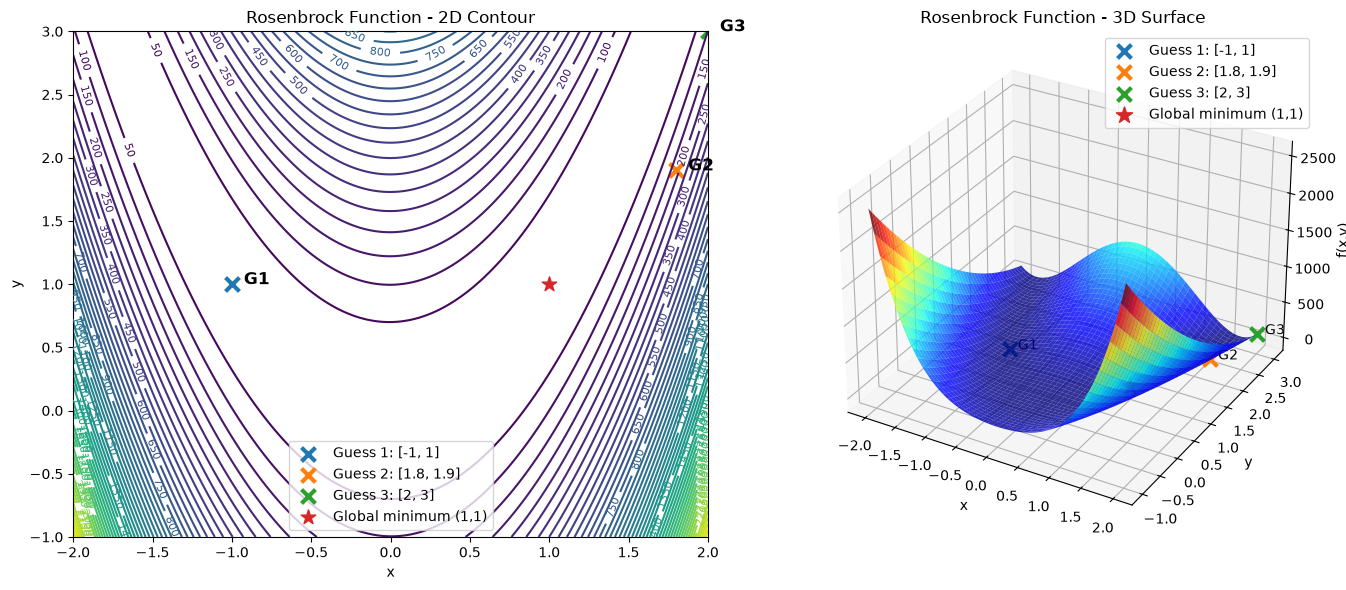


========== SCIPY RESULTS ==========
Initial guess: [-1, 1], Result: [0.9999955 0.999991 ], Value: 2.0211104546875202e-11, Success: True, Iterations: 31, Time: 0.0030 sec
Initial guess: [1.8, 1.9], Result: [0.99999557 0.99999109], Value: 1.9864077380606558e-11, Success: False, Iterations: 20, Time: 0.0044 sec
Initial guess: [2, 3], Result: [0.99999549 0.99999097], Value: 2.035876611125744e-11, Success: True, Iterations: 22, Time: 0.0020 sec

========== PYGAD RESULTS ==========


/Users/srivathsan/miniconda3/envs/mude-base/lib/python3.12/site-packages/pygad/utils/validation.py:966: UserWarning: The percentage of genes to mutate (mutation_percent_genes=10) resulted in selecting (0) genes. The number of genes to mutate is set to 1 (mutation_num_genes=1).
If you do not want to mutate any gene, please set mutation_type=None.
  warnings.warn(


Initial guess: [-1, 1], Solution: [0.99403978 0.98799269], Value: 3.7022067709780585e-05, Iterations: 2000, Time: 0.4112 sec
Initial guess: [1.8, 1.9], Solution: [1.00861133 1.01762171], Value: 8.471022482012615e-05, Iterations: 2000, Time: 0.3284 sec
Initial guess: [2, 3], Solution: [1.01199351 1.02391063], Value: 0.0001486943695380762, Iterations: 2000, Time: 0.3267 sec


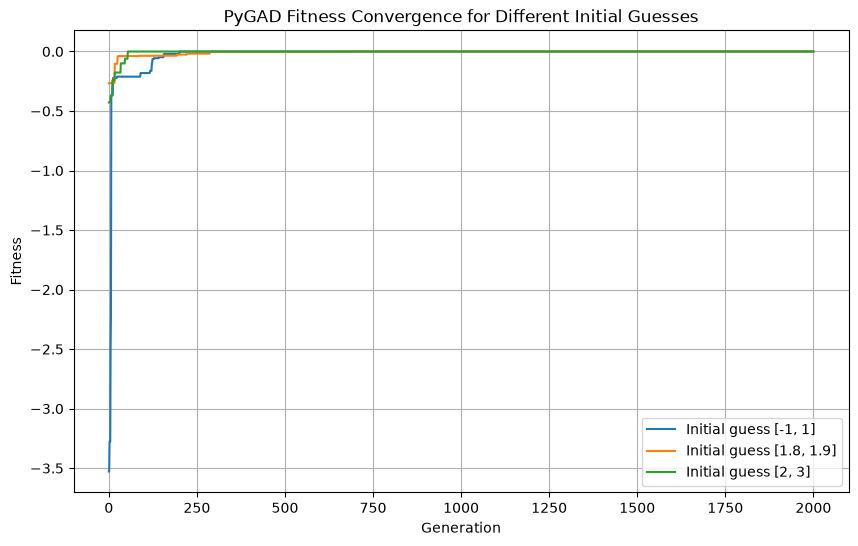

In [10]:
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import pygad

# ============================================================
# Define Rosenbrock function
# ============================================================

def rosenbrock(x):
    return (1 - x[0])**2 + 100 * (x[1] - x[0]**2)**2


# ============================================================
# 2D & 3D plots
# ============================================================

# ============================================================
# 2D & 3D plots with initial guesses
# ============================================================

x_range = np.linspace(-2, 2, 400)
y_range = np.linspace(-1, 3, 400)

X, Y = np.meshgrid(x_range, y_range)
Z = rosenbrock([X, Y])

# Initial guesses
init_guesses = [
    [-1, 1],
    [1.8, 1.9],
    [2, 3]
]

# ------------------------------------------------------------
# Create figure
# ------------------------------------------------------------

fig = plt.figure(figsize=(14, 6))

# ============================================================
# 2D CONTOUR PLOT
# ============================================================

ax1 = fig.add_subplot(121)

cp = ax1.contour(
    X,
    Y,
    Z,
    levels=50
)

ax1.clabel(cp, inline=True, fontsize=8)

ax1.set_title("Rosenbrock Function - 2D Contour")
ax1.set_xlabel("x")
ax1.set_ylabel("y")

# Mark initial guesses
for i, guess in enumerate(init_guesses):

    ax1.scatter(
        guess[0],
        guess[1],
        s=100,
        marker='x',
        linewidths=3,
        label=f"Guess {i+1}: {guess}"
    )

    ax1.annotate(
        f"  G{i+1}",
        (guess[0], guess[1]),
        fontsize=12,
        fontweight='bold'
    )

# Mark global minimum
ax1.scatter(
    1,
    1,
    s=120,
    marker='*',
    label="Global minimum (1,1)"
)

ax1.legend()


# ============================================================
# 3D SURFACE PLOT
# ============================================================

ax2 = fig.add_subplot(122, projection='3d')

ax2.plot_surface(
    X,
    Y,
    Z,
    cmap='jet',
    alpha=0.8
)

ax2.set_title("Rosenbrock Function - 3D Surface")
ax2.set_xlabel("x")
ax2.set_ylabel("y")
ax2.set_zlabel("f(x,y)")

# Mark initial guesses in 3D
for i, guess in enumerate(init_guesses):

    x0 = guess[0]
    y0 = guess[1]

    z0 = rosenbrock(guess)

    ax2.scatter(
        x0,
        y0,
        z0,
        s=100,
        marker='x',
        linewidths=3,
        label=f"Guess {i+1}: {guess}"
    )

    ax2.text(
        x0,
        y0,
        z0,
        f"  G{i+1}",
        fontsize=10
    )

# Mark global minimum
ax2.scatter(
    1,
    1,
    rosenbrock([1, 1]),
    s=150,
    marker='*',
    label="Global minimum (1,1)"
)

ax2.legend()

plt.tight_layout()
plt.show()


# ============================================================
# Initial guesses
# ============================================================

init_guesses = [
    [-1, 1],
    [1.8, 1.9],
    [2, 3]
]


# ============================================================
# Scipy Optimization
# ============================================================

print("\n========== SCIPY RESULTS ==========")

for guess in init_guesses:

    start_time = time.perf_counter()

    result = minimize(
        rosenbrock,
        guess,
        method='BFGS'
    )

    end_time = time.perf_counter()

    elapsed_time = end_time - start_time

    print(
        f"Initial guess: {guess}, "
        f"Result: {result.x}, "
        f"Value: {result.fun}, "
        f"Success: {result.success}, "
        f"Iterations: {result.nit}, "
        f"Time: {elapsed_time:.4f} sec"
    )


# ============================================================
# PyGAD Optimization
# ============================================================

def fitness_func(ga_instance, solution, solution_idx):

    # PyGAD maximizes fitness
    # Rosenbrock is minimized
    return -rosenbrock(solution)


print("\n========== PYGAD RESULTS ==========")

# Store fitness history for all 3 guesses
fitness_histories = []

for guess in init_guesses:

    start_time = time.perf_counter()

    # Create initial population around the initial guess
    initial_population = np.array([
        np.array(guess) + np.random.uniform(-0.5, 0.5, 2)
        for _ in range(20)
    ])

    ga_instance = pygad.GA(
        num_generations=2000,
        sol_per_pop=20,
        num_genes=2,
        num_parents_mating=8,
        fitness_func=fitness_func,

        # Use the population generated around the guess
        initial_population=initial_population
    )

    ga_instance.run()

    solution, solution_fitness, _ = ga_instance.best_solution()

    iters = ga_instance.generations_completed

    end_time = time.perf_counter()

    elapsed_time = end_time - start_time

    print(
        f"Initial guess: {guess}, "
        f"Solution: {solution}, "
        f"Value: {rosenbrock(solution)}, "
        f"Iterations: {iters}, "
        f"Time: {elapsed_time:.4f} sec"
    )

    # Store fitness history
    fitness_histories.append(
        ga_instance.best_solutions_fitness
    )


# ============================================================
# Combined Fitness Plot
# ============================================================

plt.figure(figsize=(10, 6))

for i, fitness_history in enumerate(fitness_histories):

    plt.plot(
        fitness_history,
        label=f"Initial guess {init_guesses[i]}"
    )

plt.xlabel("Generation")
plt.ylabel("Fitness")
plt.title("PyGAD Fitness Convergence for Different Initial Guesses")

plt.legend()
plt.grid(True)

plt.show()

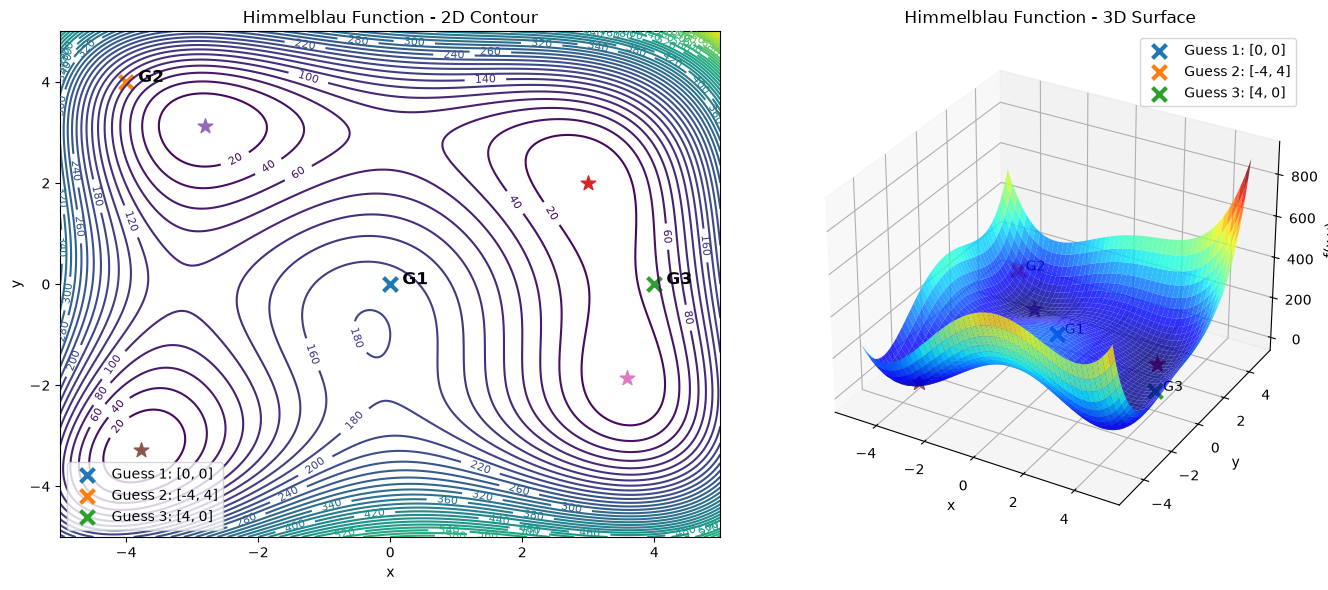


========== SCIPY RESULTS ==========
Initial guess: [0, 0], Result: [2.99999994 1.99999999], Value: 1.3782273267389757e-13, Success: True, Iterations: 10, Time: 0.0012 sec
Initial guess: [-4, 4], Result: [-2.80511803  3.13131251], Value: 1.0206445317695741e-13, Success: True, Iterations: 10, Time: 0.0009 sec
Initial guess: [4, 0], Result: [ 3.58442834 -1.84812653], Value: 2.263863966347075e-16, Success: True, Iterations: 8, Time: 0.0007 sec

========== PYGAD RESULTS ==========
Initial guess: [0, 0], Solution: [3.00008202 1.99988055], Value: 2.9550818220579e-07, Iterations: 2000, Time: 0.3589 sec
Initial guess: [-4, 4], Solution: [-2.80517491  3.13168626], Value: 5.695808592564708e-06, Iterations: 2000, Time: 0.3264 sec
Initial guess: [4, 0], Solution: [ 3.58475189 -1.84846001], Value: 6.366685580409683e-06, Iterations: 2000, Time: 0.3434 sec


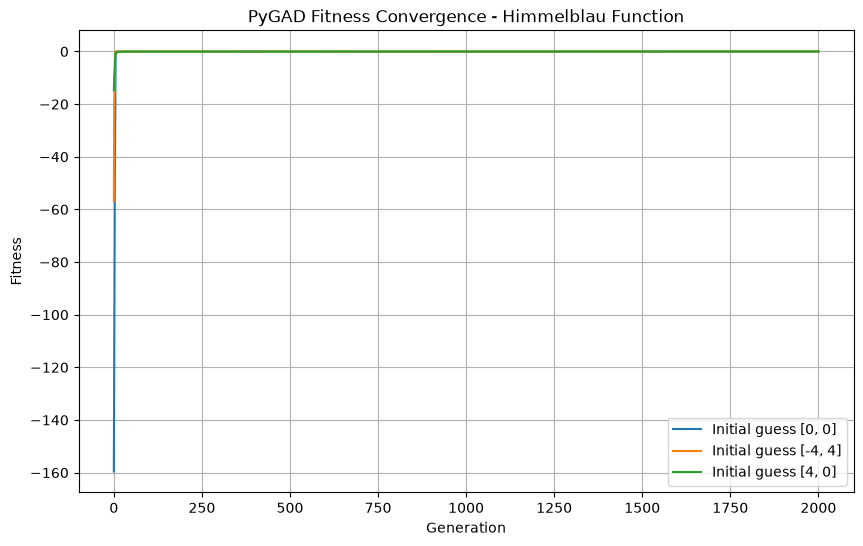

In [11]:
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import pygad


# ============================================================
# Define Himmelblau function
# ============================================================

def himmelblau(x):
    return (x[0]**2 + x[1] - 11)**2 + \
           (x[0] + x[1]**2 - 7)**2


# ============================================================
# Initial guesses
# ============================================================

init_guesses = [
    [0, 0],
    [-4, 4],
    [4, 0]
]


# ============================================================
# 2D & 3D plots with initial guesses
# ============================================================

x_range = np.linspace(-5, 5, 400)
y_range = np.linspace(-5, 5, 400)

X, Y = np.meshgrid(x_range, y_range)

Z = himmelblau([X, Y])


# ------------------------------------------------------------
# Create figure
# ------------------------------------------------------------

fig = plt.figure(figsize=(14, 6))


# ============================================================
# 2D CONTOUR PLOT
# ============================================================

ax1 = fig.add_subplot(121)

cp = ax1.contour(
    X,
    Y,
    Z,
    levels=50
)

ax1.clabel(
    cp,
    inline=True,
    fontsize=8
)

ax1.set_title("Himmelblau Function - 2D Contour")
ax1.set_xlabel("x")
ax1.set_ylabel("y")


# ------------------------------------------------------------
# Mark initial guesses
# ------------------------------------------------------------

for i, guess in enumerate(init_guesses):

    ax1.scatter(
        guess[0],
        guess[1],
        s=100,
        marker='x',
        linewidths=3,
        label=f"Guess {i+1}: {guess}"
    )

    ax1.annotate(
        f"  G{i+1}",
        (guess[0], guess[1]),
        fontsize=12,
        fontweight='bold'
    )


# ------------------------------------------------------------
# Mark four global minima
# ------------------------------------------------------------

global_minima = [
    [3, 2],
    [-2.805118, 3.131312],
    [-3.779310, -3.283186],
    [3.584428, -1.848126]
]

for minimum in global_minima:

    ax1.scatter(
        minimum[0],
        minimum[1],
        s=120,
        marker='*'
    )


ax1.legend()


# ============================================================
# 3D SURFACE PLOT
# ============================================================

ax2 = fig.add_subplot(122, projection='3d')

ax2.plot_surface(
    X,
    Y,
    Z,
    cmap='jet',
    alpha=0.8
)

ax2.set_title("Himmelblau Function - 3D Surface")
ax2.set_xlabel("x")
ax2.set_ylabel("y")
ax2.set_zlabel("f(x,y)")


# ------------------------------------------------------------
# Mark initial guesses in 3D
# ------------------------------------------------------------

for i, guess in enumerate(init_guesses):

    x0 = guess[0]
    y0 = guess[1]

    z0 = himmelblau(guess)

    ax2.scatter(
        x0,
        y0,
        z0,
        s=100,
        marker='x',
        linewidths=3,
        label=f"Guess {i+1}: {guess}"
    )

    ax2.text(
        x0,
        y0,
        z0,
        f"  G{i+1}",
        fontsize=10
    )


# ------------------------------------------------------------
# Mark four global minima in 3D
# ------------------------------------------------------------

for minimum in global_minima:

    ax2.scatter(
        minimum[0],
        minimum[1],
        himmelblau(minimum),
        s=150,
        marker='*'
    )


ax2.legend()

plt.tight_layout()
plt.show()


# ============================================================
# Scipy Optimization
# ============================================================

print("\n========== SCIPY RESULTS ==========")

for guess in init_guesses:

    start_time = time.perf_counter()

    result = minimize(
        himmelblau,
        guess,
        method='BFGS'
    )

    end_time = time.perf_counter()

    elapsed_time = end_time - start_time

    print(
        f"Initial guess: {guess}, "
        f"Result: {result.x}, "
        f"Value: {result.fun}, "
        f"Success: {result.success}, "
        f"Iterations: {result.nit}, "
        f"Time: {elapsed_time:.4f} sec"
    )


# ============================================================
# PyGAD Optimization
# ============================================================

def fitness_func(ga_instance, solution, solution_idx):

    # PyGAD maximizes fitness
    # Himmelblau is minimized
    return -himmelblau(solution)


print("\n========== PYGAD RESULTS ==========")


# Store fitness history for all 3 guesses
fitness_histories = []


for guess in init_guesses:

    start_time = time.perf_counter()


    # --------------------------------------------------------
    # Create initial population around the initial guess
    # --------------------------------------------------------

    initial_population = np.array([
        np.array(guess) + np.random.uniform(-0.5, 0.5, 2)
        for _ in range(20)
    ])


    # --------------------------------------------------------
    # Create GA
    # --------------------------------------------------------

    ga_instance = pygad.GA(
        num_generations=2000,
        sol_per_pop=20,
        num_genes=2,
        num_parents_mating=8,
        fitness_func=fitness_func,

        # Use population generated around initial guess
        initial_population=initial_population
    )


    # --------------------------------------------------------
    # Run GA
    # --------------------------------------------------------

    ga_instance.run()


    # --------------------------------------------------------
    # Best solution
    # --------------------------------------------------------

    solution, solution_fitness, _ = \
        ga_instance.best_solution()


    iters = ga_instance.generations_completed


    end_time = time.perf_counter()

    elapsed_time = end_time - start_time


    print(
        f"Initial guess: {guess}, "
        f"Solution: {solution}, "
        f"Value: {himmelblau(solution)}, "
        f"Iterations: {iters}, "
        f"Time: {elapsed_time:.4f} sec"
    )


    # --------------------------------------------------------
    # Store fitness history
    # --------------------------------------------------------

    fitness_histories.append(
        ga_instance.best_solutions_fitness
    )


# ============================================================
# Combined Fitness Plot
# ============================================================

plt.figure(figsize=(10, 6))


for i, fitness_history in enumerate(fitness_histories):

    plt.plot(
        fitness_history,
        label=f"Initial guess {init_guesses[i]}"
    )


plt.xlabel("Generation")
plt.ylabel("Fitness")

plt.title(
    "PyGAD Fitness Convergence - Himmelblau Function"
)

plt.legend()
plt.grid(True)

plt.show()